In [92]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_auc_score,
    recall_score,
    average_precision_score,
    precision_recall_curve,
    f1_score
)

In [93]:
df = pd.read_csv('/content/train.csv')
df.head(20)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1
5,5,Cash loans,F,0,135000.0,247500.0,19971.0,247500.0,Commercial associate,Secondary / secondary special,...,Transport: type 4,NaN,0.552871,NaN,-307.0,NaN,NaN,NaN,NaN,1
6,6,Cash loans,F,0,189000.0,332946.0,17127.0,238500.0,Commercial associate,Secondary / secondary special,...,Trade: type 3,NaN,0.658005,0.399676,-1918.0,0.0,0.0,0.0,3.0,0
7,7,Cash loans,M,0,157500.0,203760.0,24309.0,180000.0,Working,Higher education,...,Business Entity Type 3,NaN,0.287687,NaN,0.0,NaN,NaN,NaN,NaN,1
8,8,Cash loans,M,1,324000.0,808650.0,22234.5,675000.0,State servant,Higher education,...,Military,NaN,0.707878,0.629674,-1.0,0.0,0.0,0.0,0.0,0
9,9,Cash loans,F,1,180000.0,207117.0,16492.5,171000.0,Working,Secondary / secondary special,...,Self-employed,0.509716,0.277001,NaN,-905.0,NaN,NaN,NaN,NaN,1


In [94]:
df.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,...,171202.000000,52274.000000,1.708330e+05,116616.000000,171202.000000,148086.000000,148086.000000,148086.000000,148086.000000,171202.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,63960.411969,-4994.982524,...,2.053726,0.501692,5.145083e-01,0.511177,-962.407773,0.006652,0.268418,0.267547,1.903644,0.080729
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,141401.513149,3525.760241,...,0.508718,0.210950,1.912729e-01,0.194778,826.277244,0.086204,0.921022,0.914532,1.872237,0.272420
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,1.000000,0.017095,8.173617e-08,0.000527,-4173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-2772.000000,-7490.000000,...,2.000000,0.333353,3.920925e-01,0.370650,-1568.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1215.000000,-4515.000000,...,2.000000,0.505858,5.662998e-01,0.537070,-757.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-288.000000,-2008.000000,...,2.000000,0.674595,6.641587e-01,0.669057,-274.000000,0.000000,0.000000,0.000000,3.000000,0.000000
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,365243.000000,0.000000,...,3.000000,0.947649,8.549997e-01,0.896010,0.000000,4.000000,23.000000,261.000000,23.000000,1.000000


In [95]:
df.shape

(171202, 34)

In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  object 
 2   CODE_GENDER                 171202 non-null  object 
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  object 
 9   NAME_EDUCATION_TYPE         171202 non-null  object 
 10  NAME_FAMILY_STATUS          171202 non-null  object 
 11  NAME_HOUSING_TYPE           171202 non-null  object 
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH    

In [97]:
df.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,...,171202.000000,52274.000000,1.708330e+05,116616.000000,171202.000000,148086.000000,148086.000000,148086.000000,148086.000000,171202.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,63960.411969,-4994.982524,...,2.053726,0.501692,5.145083e-01,0.511177,-962.407773,0.006652,0.268418,0.267547,1.903644,0.080729
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,141401.513149,3525.760241,...,0.508718,0.210950,1.912729e-01,0.194778,826.277244,0.086204,0.921022,0.914532,1.872237,0.272420
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,1.000000,0.017095,8.173617e-08,0.000527,-4173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-2772.000000,-7490.000000,...,2.000000,0.333353,3.920925e-01,0.370650,-1568.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1215.000000,-4515.000000,...,2.000000,0.505858,5.662998e-01,0.537070,-757.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-288.000000,-2008.000000,...,2.000000,0.674595,6.641587e-01,0.669057,-274.000000,0.000000,0.000000,0.000000,3.000000,0.000000
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,365243.000000,0.000000,...,3.000000,0.947649,8.549997e-01,0.896010,0.000000,4.000000,23.000000,261.000000,23.000000,1.000000


In [98]:
df.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0


In [99]:
df.duplicated().sum()

np.int64(0)

In [100]:
print("XNA in CODE_GENDER      :", (df['CODE_GENDER'] == 'XNA').sum())
print("XNA in ORGANIZATION_TYPE:", (df['ORGANIZATION_TYPE'] == 'XNA').sum())
print("DAYS_EMPLOYED == 365243 :", (df['DAYS_EMPLOYED'] == 365243).sum())

XNA in CODE_GENDER      : 4
XNA in ORGANIZATION_TYPE: 30898
DAYS_EMPLOYED == 365243 : 30898


In [101]:
df = df.drop(columns=['SK_ID_CURR'])
df = df.replace('XNA', np.nan)
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
df.isnull().sum()[df.isnull().sum() > 0]

,0
CODE_GENDER,4
DAYS_EMPLOYED,30898
OWN_CAR_AGE,112992
CNT_FAM_MEMBERS,2
ORGANIZATION_TYPE,30898
EXT_SOURCE_1,118928
EXT_SOURCE_2,369
EXT_SOURCE_3,54586
AMT_REQ_CREDIT_BUREAU_HOUR,23116
AMT_REQ_CREDIT_BUREAU_MON,23116


In [102]:
df['IS_UNEMPLOYED_OR_RETIRED'] = df['DAYS_EMPLOYED'].isna().astype(int)
df['HAS_CAR'] = df['OWN_CAR_AGE'].notna().astype(int)

df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365
df['YEARS_EMPLOYED'] = -df['DAYS_EMPLOYED'] / 365
df = df.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'])

In [103]:
df_corr = df.copy()
df_corr['CODE_GENDER'] = df_corr['CODE_GENDER'].map({'M': 1, 'F': 0})

correlation = df_corr.corr(numeric_only=True)
print(correlation['TARGET'].sort_values(ascending=False))

TARGET                        1.000000
REGION_RATING_CLIENT          0.058984
DAYS_LAST_PHONE_CHANGE        0.055194
CODE_GENDER                   0.054452
DAYS_ID_PUBLISH               0.052567
FLAG_EMP_PHONE                0.045646
DAYS_REGISTRATION             0.041669
OWN_CAR_AGE                   0.040035
FLAG_WORK_PHONE               0.029102
AMT_REQ_CREDIT_BUREAU_YEAR    0.019691
CNT_CHILDREN                  0.018034
CNT_FAM_MEMBERS               0.008036
FLAG_MOBIL                    0.000716
AMT_REQ_CREDIT_BUREAU_HOUR    0.000595
AMT_REQ_CREDIT_BUREAU_QRT    -0.003098
AMT_REQ_CREDIT_BUREAU_MON    -0.014177
AMT_ANNUITY                  -0.014625
AMT_INCOME_TOTAL             -0.021638
HAS_CAR                      -0.021647
AMT_CREDIT                   -0.032727
REGION_POPULATION_RELATIVE   -0.038259
AMT_GOODS_PRICE              -0.042035
IS_UNEMPLOYED_OR_RETIRED     -0.045626
YEARS_EMPLOYED               -0.073608
AGE_YEARS                    -0.079541
EXT_SOURCE_1             

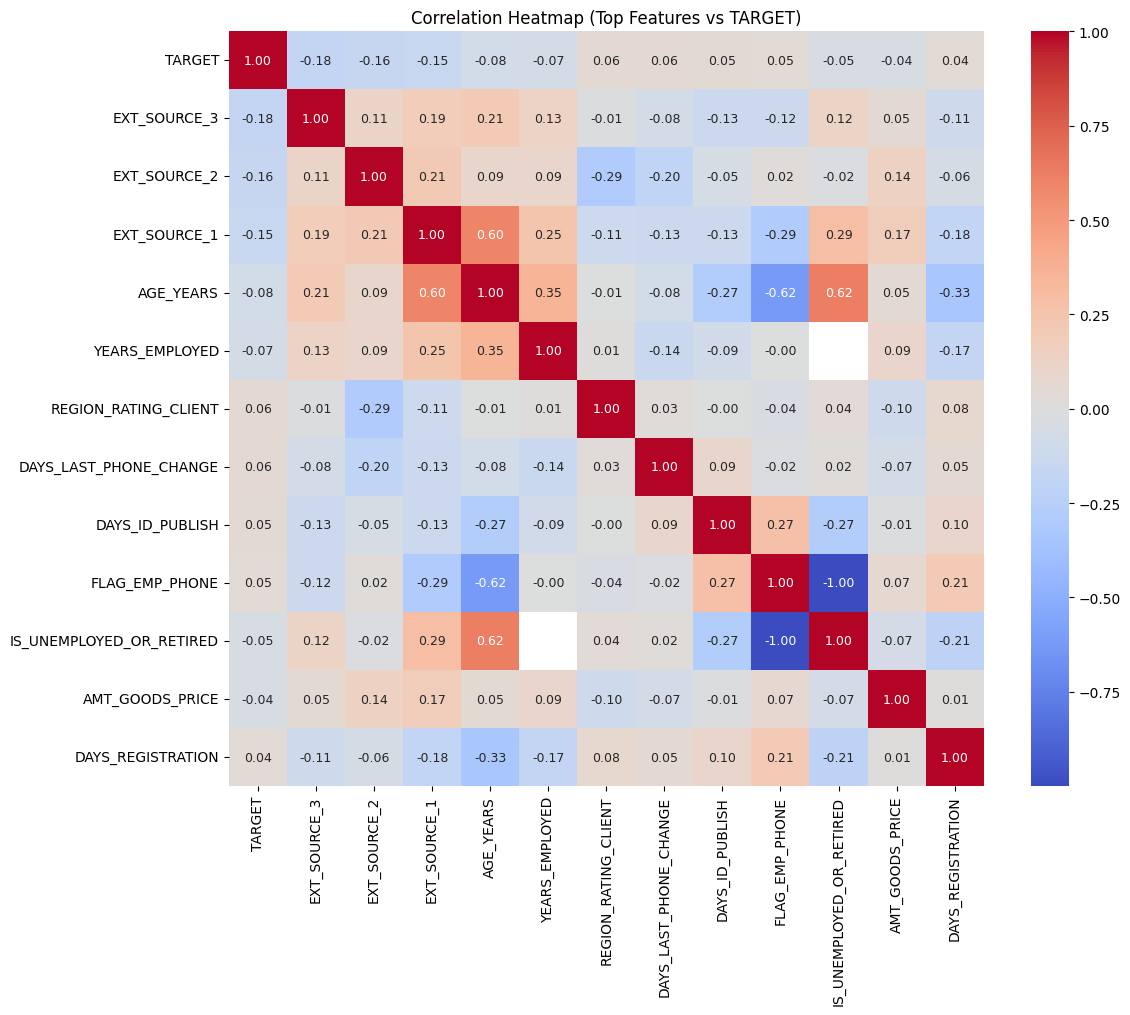

In [119]:
# === Cell 9: Heatmap ===
numeric_cols = df.select_dtypes(include='number').columns.tolist()
top_cols = (df[numeric_cols].corr()['TARGET'].abs()
            .sort_values(ascending=False).head(13).index.tolist())

plt.figure(figsize=(12, 10))
sns.heatmap(df[top_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, square=True,
            annot_kws={'size': 9})
plt.title('Correlation Heatmap (Top Features vs TARGET)')
plt.tight_layout()
plt.show()

In [105]:
print(df['FLAG_MOBIL'].value_counts())
df = df.drop(columns=['FLAG_MOBIL', 'CODE_GENDER'])

FLAG_MOBIL
1    171201
0         1
Name: count, dtype: int64


EDA

TARGET
0    157381
1     13821
Name: count, dtype: int64
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64


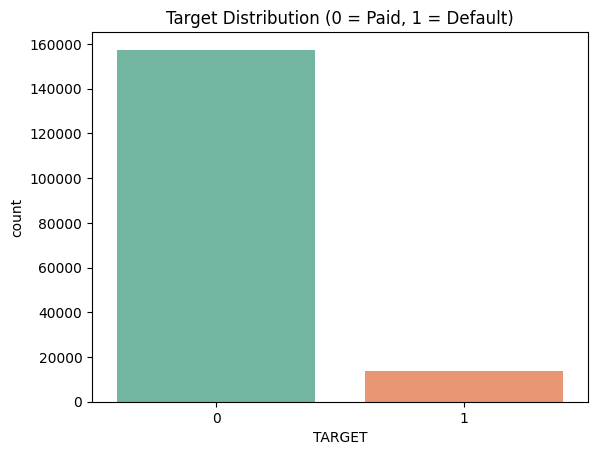

In [106]:
print(df['TARGET'].value_counts())
print(df['TARGET'].value_counts(normalize=True).round(4))
sns.countplot(data=df, x='TARGET', hue='TARGET', legend=False, palette='Set2')
plt.title('Target Distribution (0 = Paid, 1 = Default)')
plt.show()

In [107]:
num_cols = df.select_dtypes(include='number').columns.drop('TARGET').tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print("Numeric    :", len(num_cols))
print("Categorical:", len(cat_cols))

Numeric    : 25
Categorical: 7


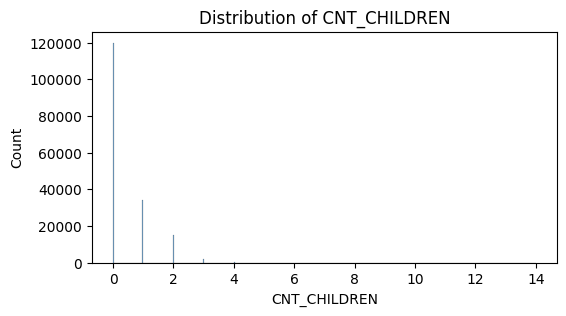

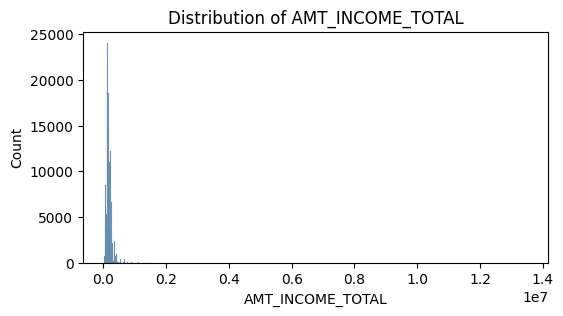

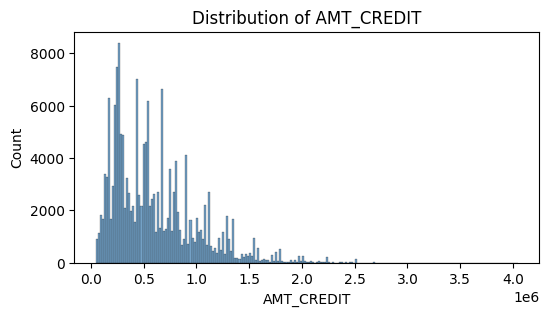

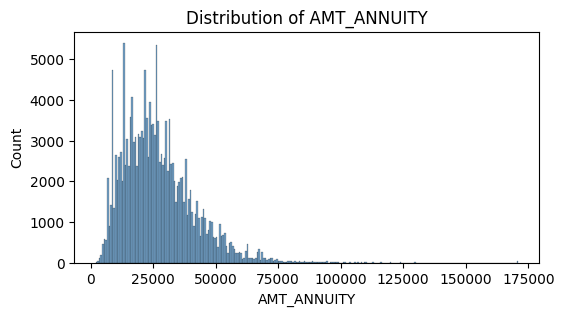

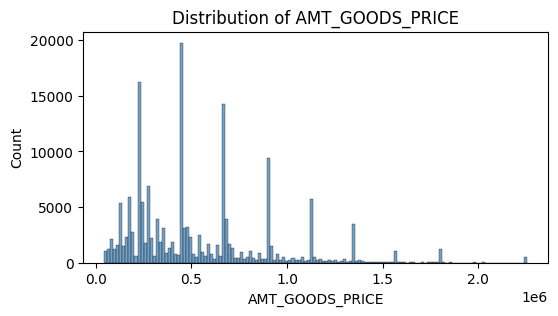

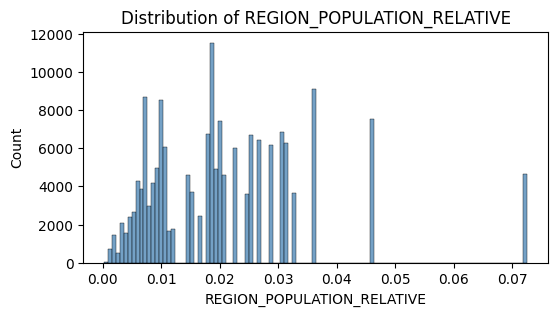

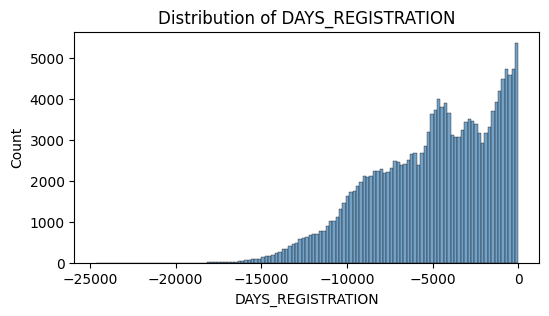

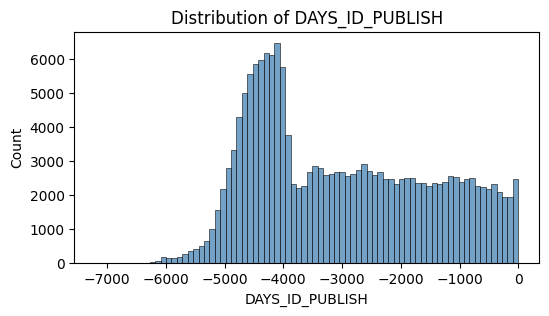

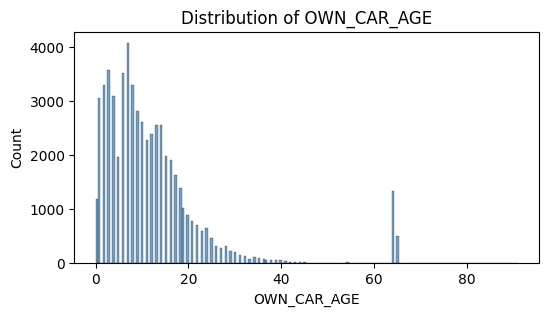

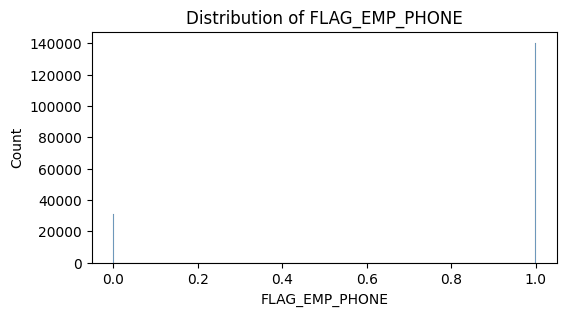

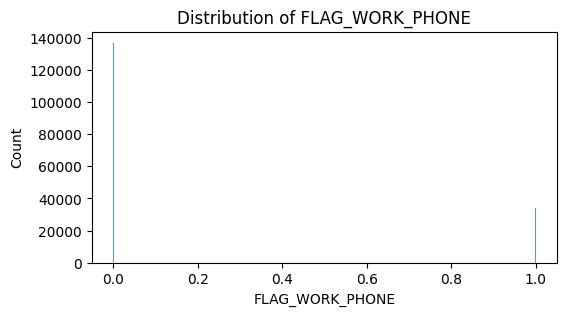

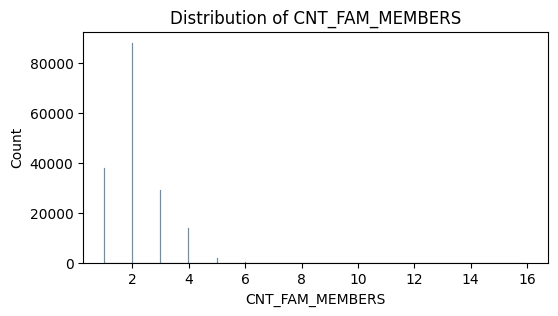

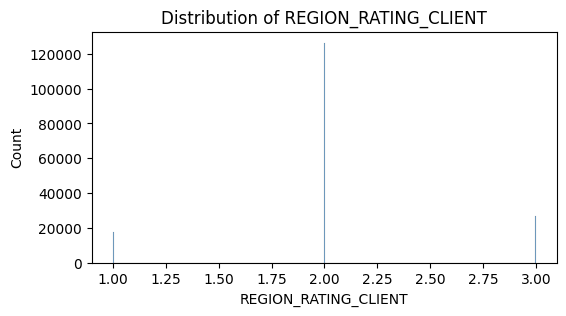

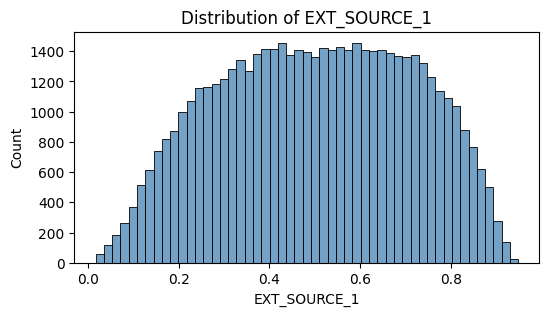

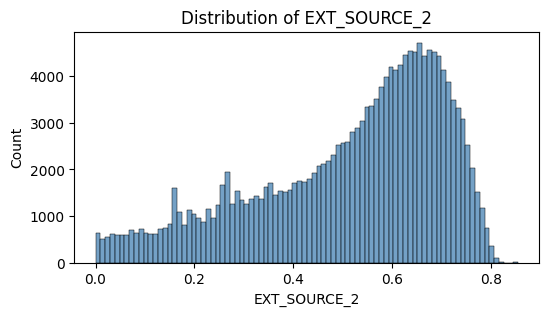

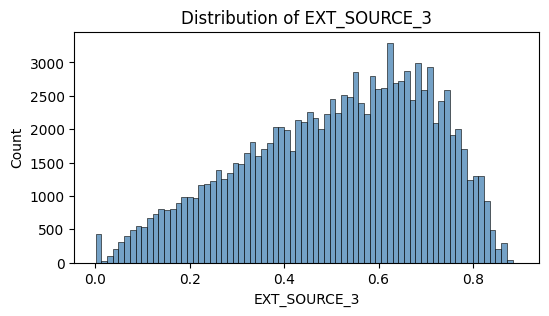

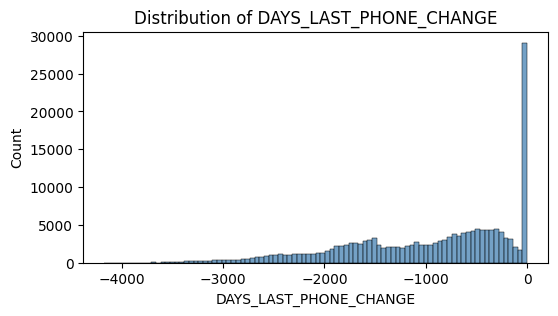

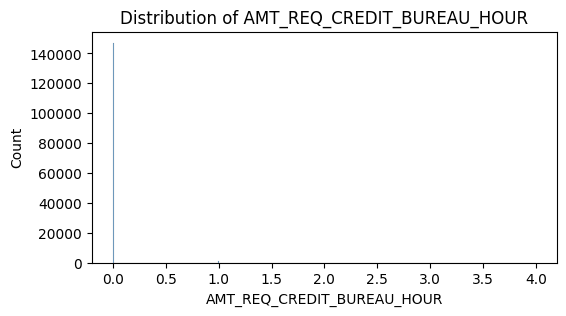

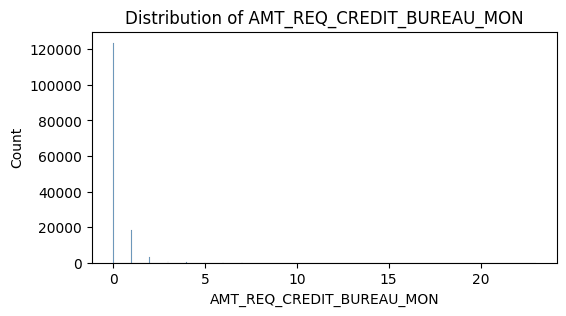

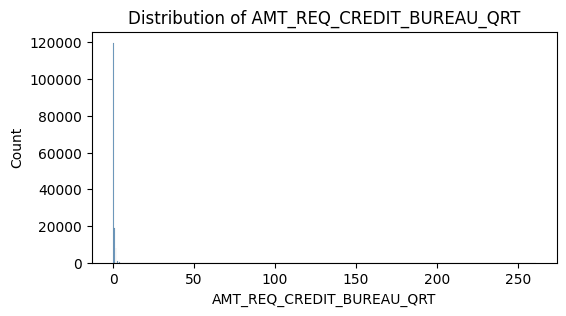

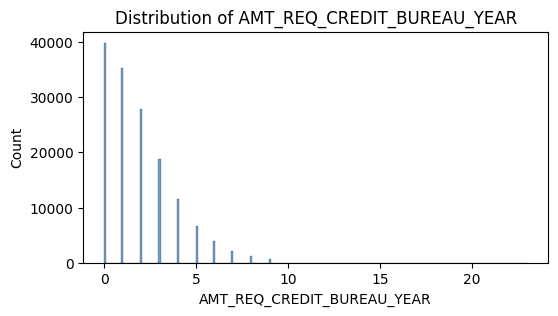

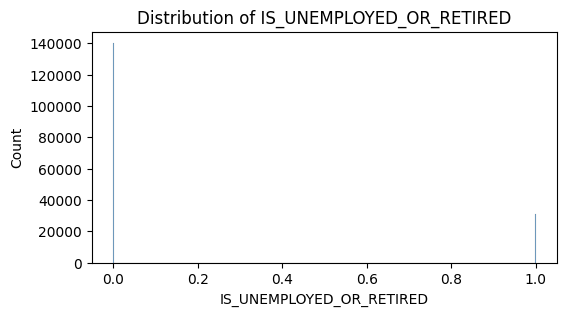

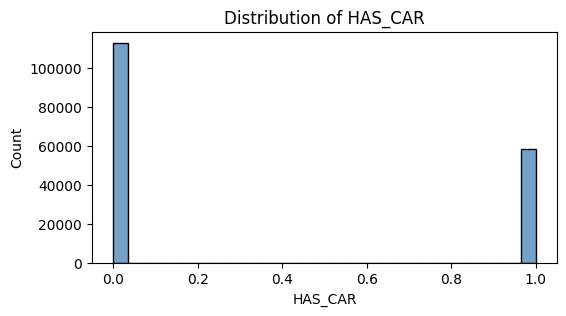

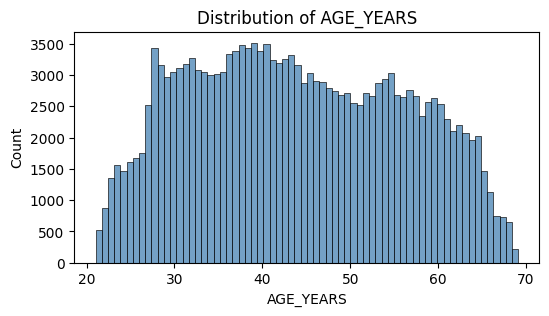

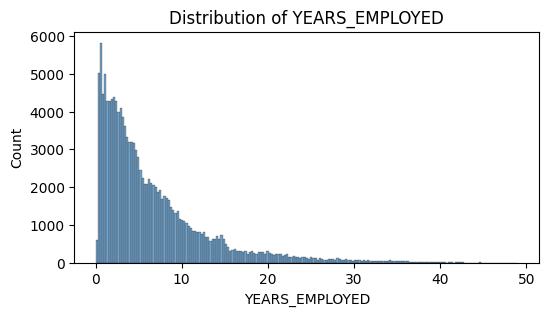

In [108]:
for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[col].dropna(), kde=False, color='steelblue')
    plt.title(f'Distribution of {col}')
    plt.show()

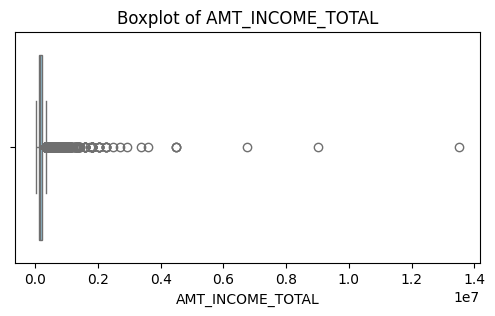

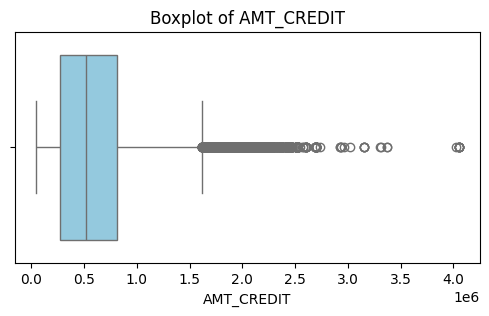

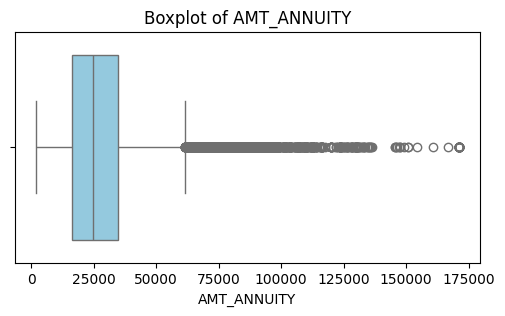

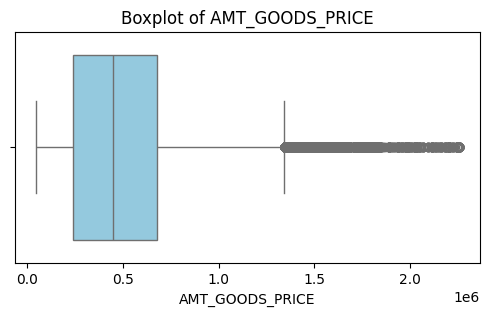

In [109]:
for col in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.show()

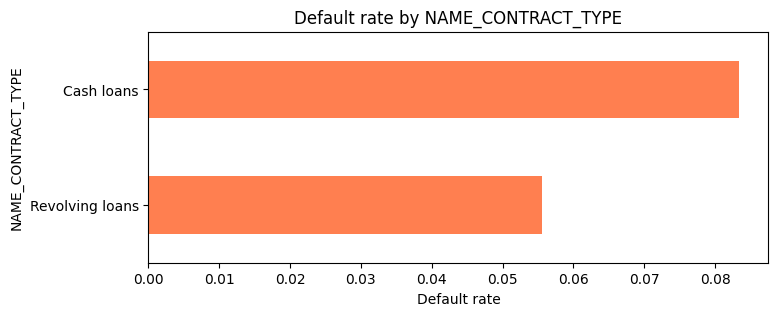

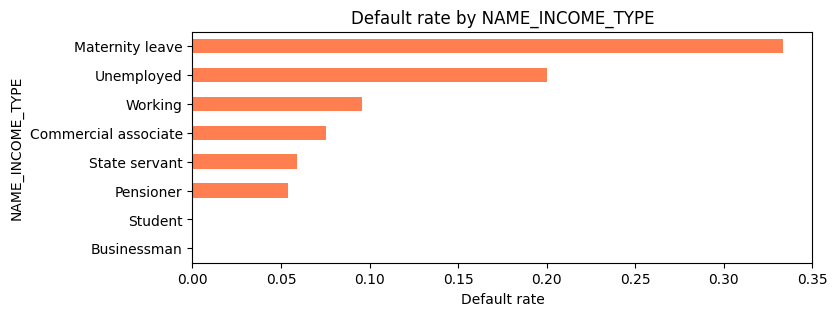

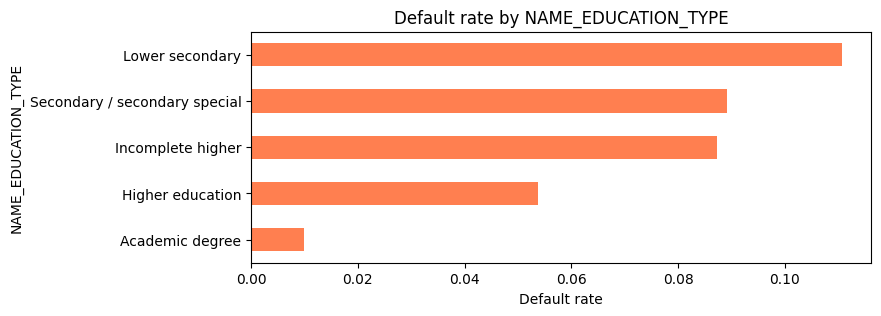

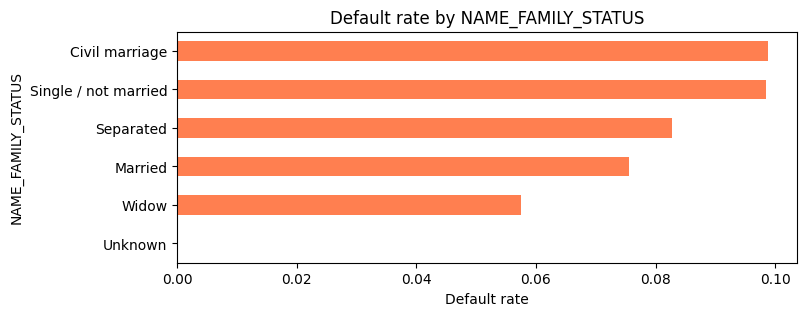

In [110]:
for col in ['NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS']:
    rate = df.groupby(col)['TARGET'].mean().sort_values()
    plt.figure(figsize=(8, 3))
    rate.plot(kind='barh', color='coral')
    plt.title(f'Default rate by {col}')
    plt.xlabel('Default rate')
    plt.show()

EXT_SOURCE_3                 -0.178317
EXT_SOURCE_2                 -0.162562
EXT_SOURCE_1                 -0.154050
AGE_YEARS                    -0.079541
YEARS_EMPLOYED               -0.073608
IS_UNEMPLOYED_OR_RETIRED     -0.045626
AMT_GOODS_PRICE              -0.042035
REGION_POPULATION_RELATIVE   -0.038259
AMT_CREDIT                   -0.032727
HAS_CAR                      -0.021647
AMT_INCOME_TOTAL             -0.021638
AMT_ANNUITY                  -0.014625
AMT_REQ_CREDIT_BUREAU_MON    -0.014177
AMT_REQ_CREDIT_BUREAU_QRT    -0.003098
AMT_REQ_CREDIT_BUREAU_HOUR    0.000595
CNT_FAM_MEMBERS               0.008036
CNT_CHILDREN                  0.018034
AMT_REQ_CREDIT_BUREAU_YEAR    0.019691
FLAG_WORK_PHONE               0.029102
OWN_CAR_AGE                   0.040035
DAYS_REGISTRATION             0.041669
FLAG_EMP_PHONE                0.045646
DAYS_ID_PUBLISH               0.052567
DAYS_LAST_PHONE_CHANGE        0.055194
REGION_RATING_CLIENT          0.058984
Name: TARGET, dtype: floa

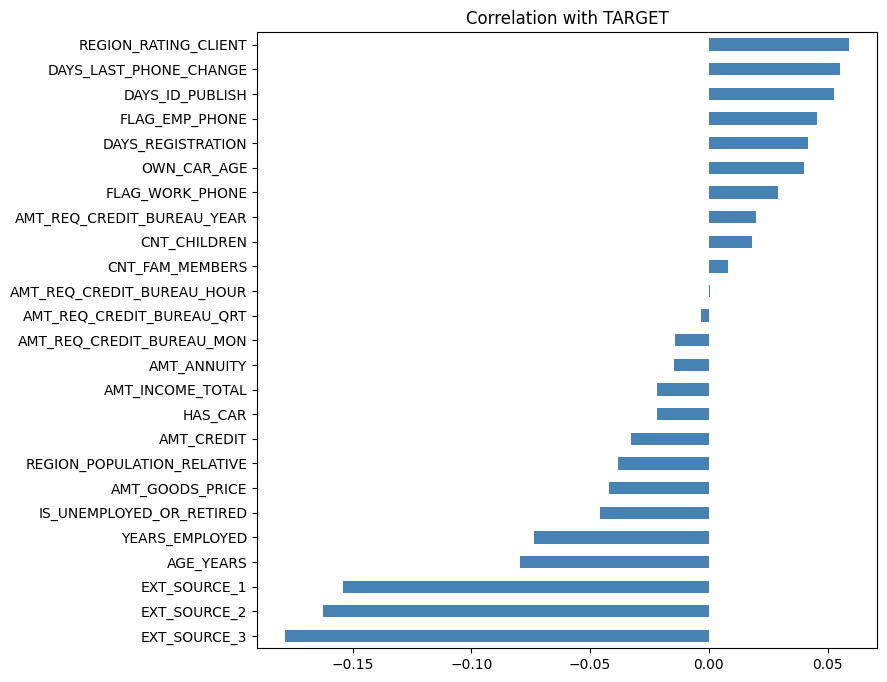

In [111]:
corr = df[num_cols + ['TARGET']].corr()['TARGET'].drop('TARGET').sort_values()
print(corr)
plt.figure(figsize=(8, 8))
corr.plot(kind='barh', color='steelblue')
plt.title('Correlation with TARGET')
plt.show()

In [112]:
df = df.dropna(subset=['TARGET'])

X = df.drop('TARGET', axis=1)
y = df['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Default rate train:", round(y_train.mean(), 4))
print("Default rate test :", round(y_test.mean(), 4))

Train: (136961, 32)  Test: (34241, 32)
Default rate train: 0.0807
Default rate test : 0.0807


In [113]:
# === Cell 19: Preprocessing ===
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, num_cols),
        ('cat', categorical_pipeline, cat_cols)
    ],
    sparse_threshold=0)

In [114]:
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=200, max_depth=4,
        min_samples_leaf=100, l2_regularization=1.0,
        class_weight='balanced', random_state=42))
])
model_pipeline.fit(X_train, y_train)
print("Model trained successfully!")

Model trained successfully!


In [115]:
y_train_pred = model_pipeline.predict(X_train)
y_test_pred = model_pipeline.predict(X_test)
train_proba = model_pipeline.predict_proba(X_train)[:, 1]
test_proba = model_pipeline.predict_proba(X_test)[:, 1]
print("Train Accuracy:", round(accuracy_score(y_train, y_train_pred), 4))
print("Test Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Train ROC-AUC:", round(roc_auc_score(y_train, train_proba), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))
print("Test Recall:", round(recall_score(y_test, y_test_pred), 4))
print("Test PR-AUC:", round(average_precision_score(y_test, test_proba), 4))
print("PR-AUC baseline (عشوائي):", round(y_test.mean(), 4))
print("-" * 50)
print(classification_report(
    y_test, y_test_pred,
    target_names=["Paid", "Default"], zero_division=0
))

Train Accuracy: 0.6909
Test Accuracy: 0.6861
Train ROC-AUC: 0.7687
Test ROC-AUC: 0.7416
Test Recall: 0.6599
Test PR-AUC: 0.2186
PR-AUC baseline (عشوائي): 0.0807
--------------------------------------------------
              precision    recall  f1-score   support

        Paid       0.96      0.69      0.80     31477
     Default       0.16      0.66      0.25      2764

    accuracy                           0.69     34241
   macro avg       0.56      0.67      0.53     34241
weighted avg       0.89      0.69      0.76     34241



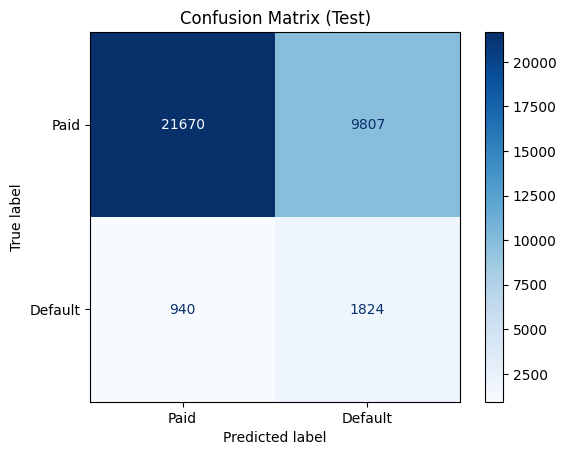

In [116]:
cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Paid", "Default"]).plot(cmap='Blues')
plt.title('Confusion Matrix (Test)')
plt.show()

In [117]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_cv = cross_val_predict(model_pipeline, X_train, y_train, cv=cv,
                             method='predict_proba', n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, proba_cv)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = thr[f1s.argmax()]
print("Best threshold:", round(best_thr, 3))

y_test_pred_tuned = (test_proba >= best_thr).astype(int)
print("Test F1 (0.5)  :", round(f1_score(y_test, y_test_pred), 4))
print("Test F1 (tuned):", round(f1_score(y_test, y_test_pred_tuned), 4))
print(classification_report(
    y_test, y_test_pred_tuned,
    target_names=["Paid", "Default"], zero_division=0
))

Best threshold: 0.634
Test F1 (0.5)  : 0.2534
Test F1 (tuned): 0.2877
              precision    recall  f1-score   support

        Paid       0.94      0.87      0.91     31477
     Default       0.22      0.42      0.29      2764

    accuracy                           0.83     34241
   macro avg       0.58      0.64      0.60     34241
weighted avg       0.89      0.83      0.86     34241



In [118]:
joblib.dump(model_pipeline, 'credit_model.pkl')
print("Complete Pipeline saved successfully!")

Complete Pipeline saved successfully!
